In [ ]:
%pip install -q roboflow scikit-learn seaborn pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 59.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.9 MB/s eta 0:00:00


In [ ]:
import json
import random
import numpy as np
import tensorflow as tf

from collections import Counter
from roboflow import Roboflow
from getpass import getpass
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from google.colab import files
from tensorflow.keras.preprocessing import image
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import os
from PIL import Image
import random
import shutil
from pathlib import Path
import glob
from collections import Counter, defaultdict
import seaborn as sns
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:


API_KEY = getpass("Enter Roboflow API Key: ")

rf = Roboflow(api_key=API_KEY)

project = rf.workspace(
    "helmi-estiawan"
).project("tomato-maturity-ieee")

dataset = project.version(2).download(
    "coco",
    location="/content/tomato_dataset"
)

DATASET_PATH = dataset.location

print("Dataset downloaded!")
print("Path:", DATASET_PATH)
print("Files:", os.listdir(DATASET_PATH))

Enter Roboflow API Key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/tomato_dataset in coco:: 100%|██████████| 1496/1496 [00:00<00:00, 7546.20it/s]

Dataset downloaded!
Path: /content/tomato_dataset
Files: ['README.dataset.txt', 'README.roboflow.txt', 'test', 'train', 'valid']


In [ ]:
annotation_path = os.path.join(
    DATASET_PATH,
    "train",
    "_annotations.coco.json"
)

with open(annotation_path, "r") as f:
    data = json.load(f)

print("Images:", len(data["images"]))
print("Annotations:", len(data["annotations"]))

print("\nClasses:")
for category in data["categories"]:
    print(category["id"], ":", category["name"])

print("\nAnnotations per class:")

counts = Counter(
    ann["category_id"]
    for ann in data["annotations"]
)

for category in data["categories"]:
    print(
        category["name"],
        ":",
        counts[category["id"]]
    )

Images: 1284
Annotations: 1284

Classes:
0 : tomato
1 : class 1
2 : class 2
3 : class 3
4 : class 4
5 : class 5
6 : class 6

Annotations per class:
tomato : 0
class 1 : 220
class 2 : 224
class 3 : 203
class 4 : 226
class 5 : 208
class 6 : 203


In [ ]:


CLASSIFICATION_PATH = "/content/tomato_classification"

# Read class definitions from training annotations
with open(
    os.path.join(DATASET_PATH, "train", "_annotations.coco.json"),
    "r"
) as f:
    train_coco = json.load(f)

# Exclude general tomato category
categories = sorted(
    [
        c for c in train_coco["categories"]
        if c["name"].strip().lower() != "tomato"
    ],
    key=lambda c: c["id"]
)

class_names = [c["name"] for c in categories]
class_to_index = {
    name: i for i, name in enumerate(class_names)
}

print("Classes:", class_names)
assert len(class_names) == 6, "Expected 6 maturity classes"

def convert_split(split):

    annotation_file = os.path.join(
        DATASET_PATH,
        split,
        "_annotations.coco.json"
    )

    with open(annotation_file, "r") as f:
        coco = json.load(f)

    images = {
        img["id"]: img
        for img in coco["images"]
    }

    local_classes = {
        c["id"]: c["name"]
        for c in coco["categories"]
    }

    counts = Counter()
    skipped = 0

    for name in class_names:
        os.makedirs(
            os.path.join(CLASSIFICATION_PATH, split, name),
            exist_ok=True
        )

    for ann in coco["annotations"]:

        class_name = local_classes[ann["category_id"]]

        if class_name not in class_to_index:
            continue

        image_info = images[ann["image_id"]]

        image_path = os.path.join(
            DATASET_PATH,
            split,
            image_info["file_name"]
        )

        if not os.path.exists(image_path):
            skipped += 1
            continue

        with Image.open(image_path) as original:
            img = original.convert("RGB")

            x, y, w, h = ann["bbox"]

            # Small margin around the tomato
            padding = 0.05

            x1 = max(0, int(x - w * padding))
            y1 = max(0, int(y - h * padding))
            x2 = min(img.width, int(x + w * (1 + padding)))
            y2 = min(img.height, int(y + h * (1 + padding)))

            if x2 <= x1 or y2 <= y1:
                skipped += 1
                continue

            crop = img.crop((x1, y1, x2, y2))

            output_file = os.path.join(
                CLASSIFICATION_PATH,
                split,
                class_name,
                f"image_{ann['image_id']}_ann_{ann['id']}.jpg"
            )

            crop.save(output_file, quality=95)
            counts[class_name] += 1

    print(f"\n{split.upper()}")
    print("Total crops:", sum(counts.values()))
    print("Skipped:", skipped)

    for name in class_names:
        print(name, ":", counts[name])

for split in ["train", "valid", "test"]:
    convert_split(split)

with open("/content/class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)

print("\nConversion completed!")

Classes: ['class 1', 'class 2', 'class 3', 'class 4', 'class 5', 'class 6']

TRAIN
Total crops: 1284
Skipped: 0
class 1 : 220
class 2 : 224
class 3 : 203
class 4 : 226
class 5 : 208
class 6 : 203

VALID
Total crops: 138
Skipped: 0
class 1 : 24
class 2 : 24
class 3 : 22
class 4 : 19
class 5 : 25
class 6 : 24

TEST
Total crops: 69
Skipped: 0
class 1 : 7
class 2 : 8
class 3 : 15
class 4 : 11
class 5 : 12
class 6 : 16

Conversion completed!


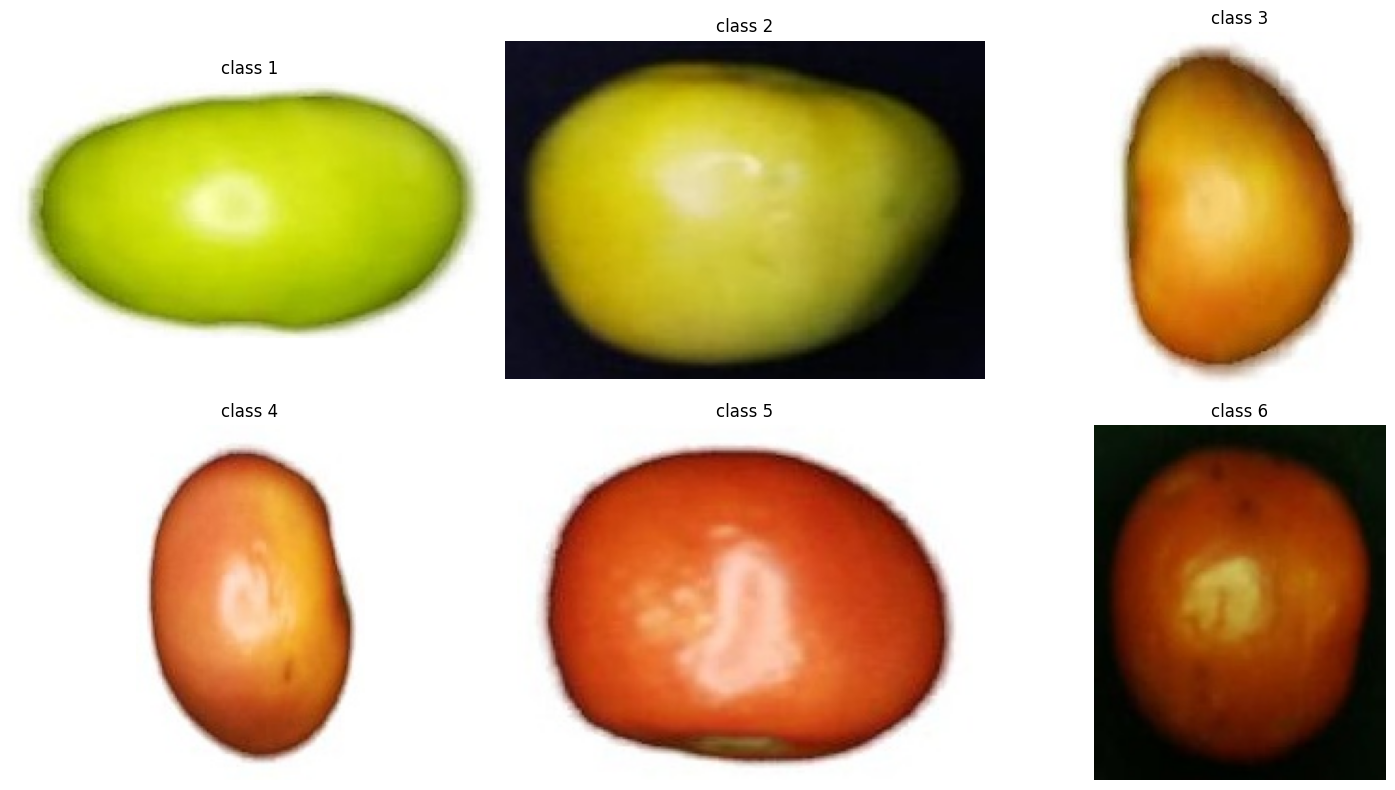

In [ ]:

plt.figure(figsize=(15, 8))

for i, class_name in enumerate(class_names):

    files = glob.glob(
        os.path.join(
            CLASSIFICATION_PATH,
            "train",
            class_name,
            "*.jpg"
        )
    )

    if not files:
        continue

    image = Image.open(random.choice(files))

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:


IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_split(split, shuffle):

    return tf.keras.utils.image_dataset_from_directory(
        os.path.join(CLASSIFICATION_PATH, split),
        labels="inferred",
        label_mode="int",
        class_names=class_names,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED
    )

train_ds = load_split("train", True)
val_ds = load_split("valid", False)
test_ds = load_split("test", False)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Datasets ready!")

Found 1284 files belonging to 6 classes.
Found 138 files belonging to 6 classes.
Found 69 files belonging to 6 classes.
Datasets ready!


In [ ]:


NUM_CLASSES = len(class_names)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# First stage: freeze backbone
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

# MobileNetV2 normalization: [0,255] -> [-1,1]
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1
)(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=l2(1e-4)
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:


STAGE1_PATH = "/content/tomato_stage1.keras"

callbacks_stage1 = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        min_delta=0.001,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        STAGE1_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=callbacks_stage1
)

Epoch 1/25
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.5357 - loss: 1.2479
Epoch 1: val_loss improved from None to 0.55119, saving model to /content/tomato_stage1.keras

Epoch 1: finished saving model to /content/tomato_stage1.keras
41/41 ━━━━━━━━━━━━━━━━━━━━ 14s 120ms/step - accuracy: 0.6488 - loss: 0.9074 - val_accuracy: 0.7826 - val_loss: 0.5512 - learning_rate: 0.0010
Epoch 2/25
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.7658 - loss: 0.5711
Epoch 2: val_loss improved from 0.55119 to 0.51684, saving model to /content/tomato_stage1.keras

Epoch 2: finished saving model to /content/tomato_stage1.keras
41/41 ━━━━━━━━━━━━━━━━━━━━ 5s 130ms/step - accuracy: 0.7710 - loss: 0.5483 - val_accuracy: 0.7681 - val_loss: 0.5168 - learning_rate: 0.0010
Epoch 3/25
40/41 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.8001 - loss: 0.5096
Epoch 3: val_loss did not improve from 0.51684
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - accuracy: 0.8123 - loss: 0.4847 - val_accuracy: 0.7681

In [ ]:
# Load best stage 1 weights
model.load_weights(STAGE1_PATH)

base_model.trainable = True

# Freeze most backbone layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

FINAL_MODEL_PATH = "/content/tomato_mobilenetv2.keras"

callbacks_stage2 = [
    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        FINAL_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks_stage2
)

model = tf.keras.models.load_model(FINAL_MODEL_PATH)

Epoch 1/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9171 - loss: 0.2378
Epoch 1: val_loss improved from None to 0.41128, saving model to /content/tomato_mobilenetv2.keras

Epoch 1: finished saving model to /content/tomato_mobilenetv2.keras
41/41 ━━━━━━━━━━━━━━━━━━━━ 12s 121ms/step - accuracy: 0.9143 - loss: 0.2259 - val_accuracy: 0.8623 - val_loss: 0.4113 - learning_rate: 1.0000e-05
Epoch 2/30
40/41 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.9299 - loss: 0.1967
Epoch 2: val_loss did not improve from 0.41128
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - accuracy: 0.9330 - loss: 0.1946 - val_accuracy: 0.8261 - val_loss: 0.4999 - learning_rate: 1.0000e-05
Epoch 3/30
40/41 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.9125 - loss: 0.2234
Epoch 3: val_loss improved from 0.41128 to 0.39932, saving model to /content/tomato_mobilenetv2.keras

Epoch 3: finished saving model to /content/tomato_mobilenetv2.keras
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 94ms/step - accuracy: 0.9198 - loss: 0.

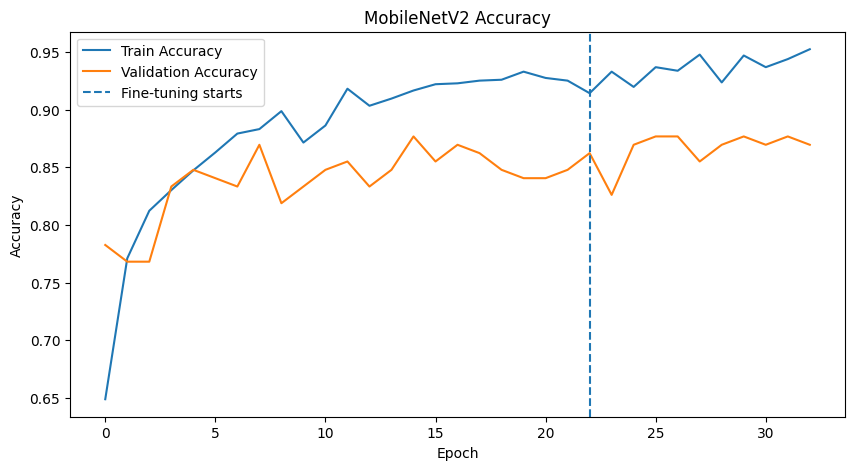

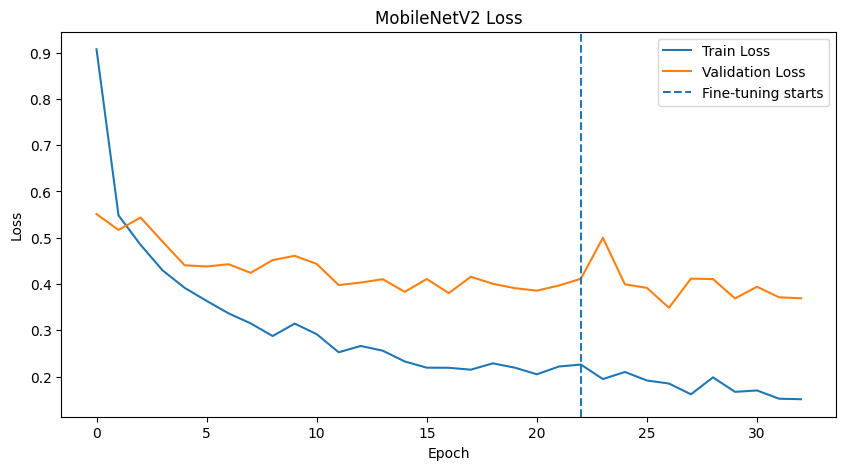

In [ ]:


train_acc = (
    history1.history["accuracy"] +
    history2.history["accuracy"]
)

val_acc = (
    history1.history["val_accuracy"] +
    history2.history["val_accuracy"]
)

train_loss = (
    history1.history["loss"] +
    history2.history["loss"]
)

val_loss = (
    history1.history["val_loss"] +
    history2.history["val_loss"]
)

plt.figure(figsize=(10, 5))

plt.plot(train_acc, label="Train Accuracy")
plt.plot(val_acc, label="Validation Accuracy")
plt.axvline(
    len(history1.history["accuracy"]),
    linestyle="--",
    label="Fine-tuning starts"
)

plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(train_loss, label="Train Loss")
plt.plot(val_loss, label="Validation Loss")
plt.axvline(
    len(history1.history["loss"]),
    linestyle="--",
    label="Fine-tuning starts"
)

plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:


y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = model.predict(
        images,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print("======== TEST RESULTS ========")

print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1 Score : {f1 * 100:.2f}%")

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

======== TEST RESULTS ========
Accuracy : 81.16%
Precision: 82.97%
Recall   : 82.04%
F1 Score : 82.31%

Classification Report:

              precision    recall  f1-score   support

     class 1       1.00      1.00      1.00         7
     class 2       1.00      0.88      0.93         8
     class 3       0.94      1.00      0.97        15
     class 4       0.82      0.82      0.82        11
     class 5       0.50      0.42      0.45        12
     class 6       0.72      0.81      0.76        16

    accuracy                           0.81        69
   macro avg       0.83      0.82      0.82        69
weighted avg       0.81      0.81      0.81        69



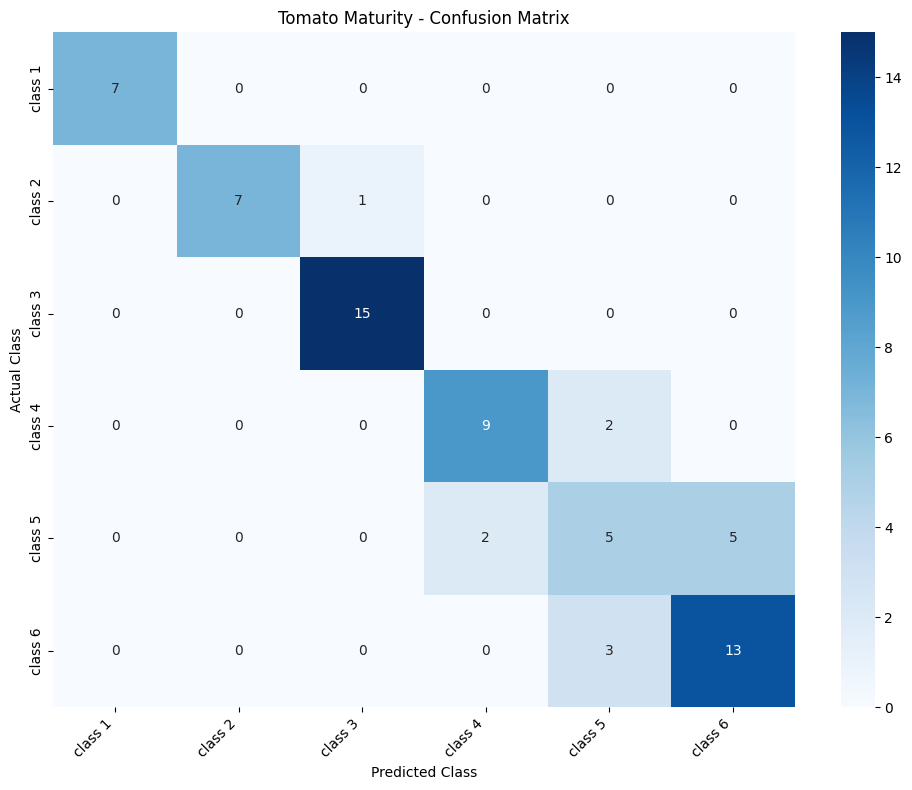

In [ ]:


cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Tomato Maturity - Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
from collections import Counter
import os
import glob

for split in ["train", "valid", "test"]:
    print(f"\n===== {split.upper()} =====")

    for class_name in class_names:
        folder = os.path.join(
            CLASSIFICATION_PATH,
            split,
            class_name
        )

        count = len(glob.glob(
            os.path.join(folder, "*.jpg")
        ))

        print(f"{class_name}: {count}")


===== TRAIN =====
class 1: 220
class 2: 224
class 3: 203
class 4: 226
class 5: 208
class 6: 203

===== VALID =====
class 1: 24
class 2: 24
class 3: 22
class 4: 19
class 5: 25
class 6: 24

===== TEST =====
class 1: 7
class 2: 8
class 3: 15
class 4: 11
class 5: 12
class 6: 16


Misclassified Class 5 images: 8


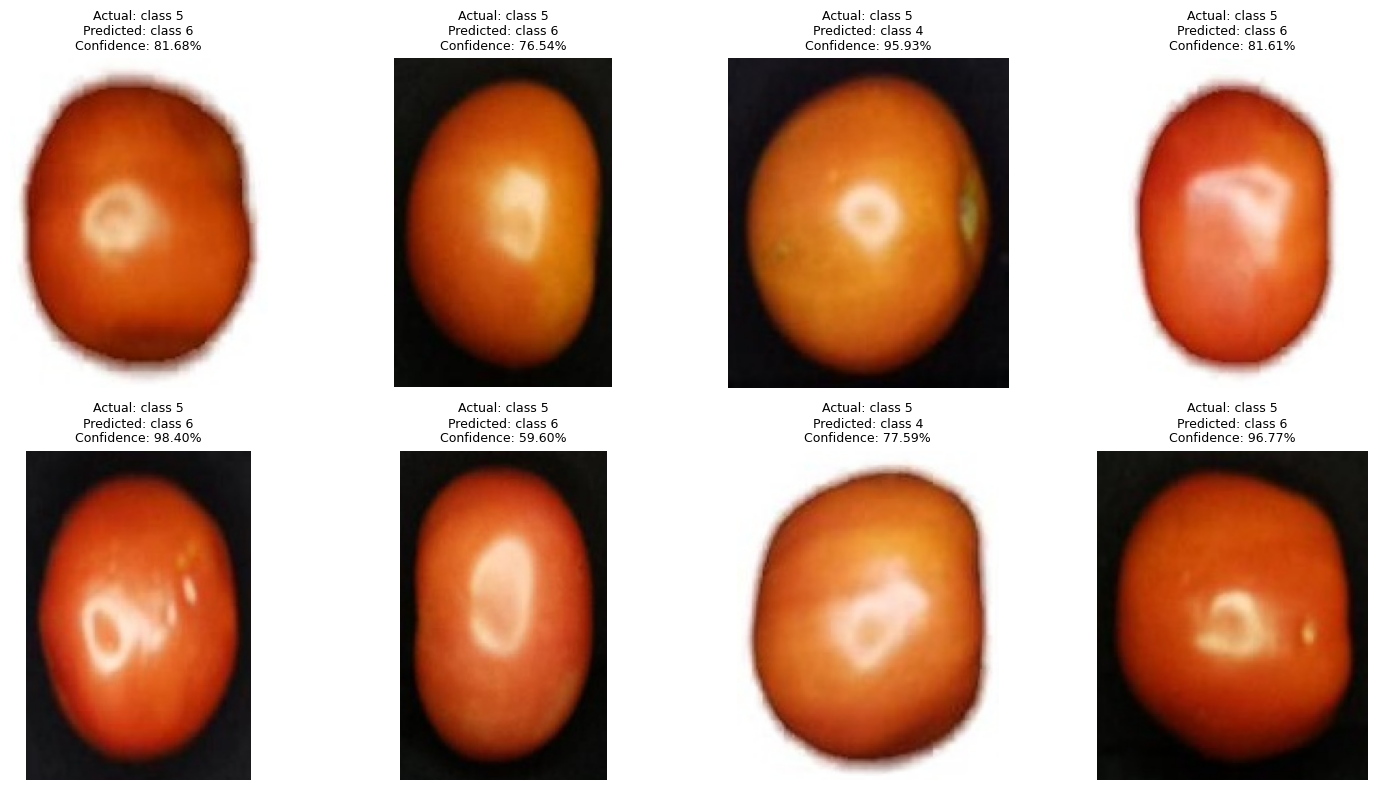

In [ ]:


# Get test image paths in the same order as test_ds
test_dir = os.path.join(
    CLASSIFICATION_PATH,
    "test"
)

test_files = []
test_labels = []

for class_idx, class_name in enumerate(class_names):
    folder = os.path.join(test_dir, class_name)

    for filename in sorted(os.listdir(folder)):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            test_files.append(os.path.join(folder, filename))
            test_labels.append(class_idx)

# Predict each file directly to ensure correct alignment
wrong_images = []

for path, true_label in zip(test_files, test_labels):

    img = Image.open(path).convert("RGB")
    img_input = img.resize((224, 224))
    img_array = np.array(img_input, dtype=np.float32)
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)[0]
    predicted_label = np.argmax(prediction)

    if true_label == 4 and predicted_label != true_label:
        wrong_images.append({
            "path": path,
            "true": class_names[true_label],
            "predicted": class_names[predicted_label],
            "confidence": prediction[predicted_label]
        })

print("Misclassified Class 5 images:", len(wrong_images))

plt.figure(figsize=(15, 4 * ((len(wrong_images) + 3) // 4)))

for i, item in enumerate(wrong_images):
    plt.subplot((len(wrong_images) + 3) // 4, 4, i + 1)
    plt.imshow(Image.open(item["path"]))
    plt.title(
        f"Actual: {item['true']}\n"
        f"Predicted: {item['predicted']}\n"
        f"Confidence: {item['confidence']:.2%}",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

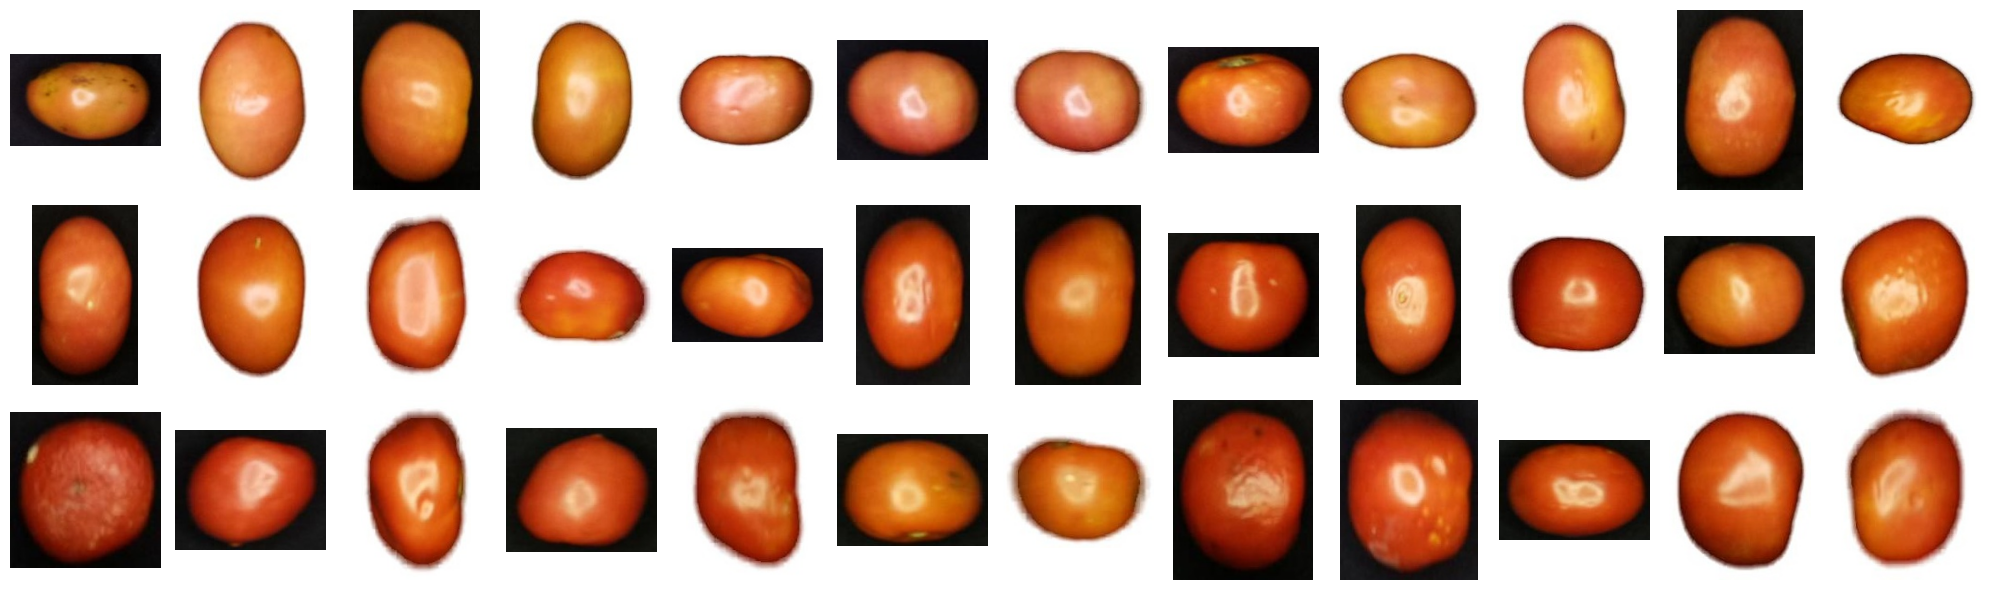

In [ ]:


random.seed(42)

selected_classes = [
    "class 4",
    "class 5",
    "class 6"
]

fig, axes = plt.subplots(3, 12, figsize=(20, 6))

for row, class_name in enumerate(selected_classes):

    folder = os.path.join(
        CLASSIFICATION_PATH,
        "train",
        class_name
    )

    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".png", ".jpeg"))
    ]

    samples = random.sample(files, min(12, len(files)))

    for col in range(12):
        ax = axes[row, col]
        ax.axis("off")

        if col < len(samples):
            image = Image.open(
                os.path.join(folder, samples[col])
            )
            ax.imshow(image)

        if col == 0:
            ax.set_ylabel(
                class_name,
                fontsize=12
            )

plt.tight_layout()
plt.show()

In [ ]:


SOURCE = Path("/content/tomato_classification")
DEST = Path("/content/tomato_classification_5classes")

NEW_CLASSES = [
    "class 1",
    "class 2",
    "class 3",
    "class 4",
    "mature_merged"
]

# Create a separate dataset
for split in ["train", "valid", "test"]:

    for class_name in NEW_CLASSES:
        (DEST / split / class_name).mkdir(
            parents=True, exist_ok=True
        )

    for old_class in [
        "class 1", "class 2", "class 3",
        "class 4", "class 5", "class 6"
    ]:

        new_class = (
            "mature_merged"
            if old_class in ["class 5", "class 6"]
            else old_class
        )

        for file in (SOURCE / split / old_class).glob("*"):

            if not file.is_file():
                continue

            # Prefix avoids duplicate filenames
            filename = f"{old_class.replace(' ', '_')}_{file.name}"

            shutil.copy2(
                file,
                DEST / split / new_class / filename
            )

print("Dataset merged successfully!")

for split in ["train", "valid", "test"]:
    print(f"\n{split.upper()}")

    for name in NEW_CLASSES:
        count = len(list((DEST / split / name).glob("*.jpg")))
        print(f"{name}: {count}")

Dataset merged successfully!

TRAIN
class 1: 220
class 2: 224
class 3: 203
class 4: 226
mature_merged: 411

VALID
class 1: 24
class 2: 24
class 3: 22
class 4: 19
mature_merged: 49

TEST
class 1: 7
class 2: 8
class 3: 15
class 4: 11
mature_merged: 28


In [ ]:
import tensorflow as tf
import numpy as np
import random

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

CLASS_NAMES = NEW_CLASSES
NUM_CLASSES = len(CLASS_NAMES)

def load_data(split, shuffle=False):

    return tf.keras.utils.image_dataset_from_directory(
        str(DEST / split),
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="int",
        class_names=CLASS_NAMES,
        shuffle=shuffle,
        seed=SEED
    )

train_ds = load_data("train", True)
val_ds = load_data("valid")
test_ds = load_data("test")

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

Found 1284 files belonging to 5 classes.
Found 138 files belonging to 5 classes.
Found 69 files belonging to 5 classes.


In [ ]:


base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.08)(x)

x = layers.Rescaling(
    scale=1./127.5,
    offset=-1
)(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.35)(x)

outputs = layers.Dense(
    5,
    activation="softmax"
)(x)

model_5 = Model(inputs, outputs)

model_5.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_5.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:


stage1_path = "/content/tomato_5_stage1.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        stage1_path,
        monitor="val_loss",
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

history1 = model_5.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=callbacks
)

Epoch 1/25
41/41 ━━━━━━━━━━━━━━━━━━━━ 14s 158ms/step - accuracy: 0.7329 - loss: 0.6566 - val_accuracy: 0.9130 - val_loss: 0.2732 - learning_rate: 0.0010
Epoch 2/25
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 83ms/step - accuracy: 0.8684 - loss: 0.3298 - val_accuracy: 0.9130 - val_loss: 0.2195 - learning_rate: 0.0010
Epoch 3/25
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 90ms/step - accuracy: 0.8847 - loss: 0.2699 - val_accuracy: 0.9275 - val_loss: 0.2153 - learning_rate: 0.0010
Epoch 4/25
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 90ms/step - accuracy: 0.9050 - loss: 0.2383 - val_accuracy: 0.9348 - val_loss: 0.1729 - learning_rate: 0.0010
Epoch 5/25
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.9299 - loss: 0.1909 - val_accuracy: 0.9348 - val_loss: 0.1779 - learning_rate: 0.0010
Epoch 6/25
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 75ms/step - accuracy: 0.9237 - loss: 0.1908 - val_accuracy: 0.9493 - val_loss: 0.1475 - learning_rate: 0.0010
Epoch 7/25
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - accuracy: 0.9315 - loss: 0.1863 - val_a

In [ ]:
model_5.load_weights(stage1_path)

base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False

model_5.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

final_path = "/content/tomato_mobilenetv2_5classes.keras"

callbacks_fine = [
    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        final_path,
        monitor="val_loss",
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7
    )
]

history2 = model_5.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks_fine
)

Epoch 1/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 14s 222ms/step - accuracy: 0.9564 - loss: 0.1212 - val_accuracy: 0.9710 - val_loss: 0.1292 - learning_rate: 1.0000e-05
Epoch 2/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 96ms/step - accuracy: 0.9626 - loss: 0.1036 - val_accuracy: 0.9710 - val_loss: 0.1240 - learning_rate: 1.0000e-05
Epoch 3/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 74ms/step - accuracy: 0.9673 - loss: 0.0793 - val_accuracy: 0.9420 - val_loss: 0.1412 - learning_rate: 1.0000e-05
Epoch 4/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.9735 - loss: 0.0699 - val_accuracy: 0.9638 - val_loss: 0.1367 - learning_rate: 1.0000e-05
Epoch 5/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step - accuracy: 0.9696 - loss: 0.0886 - val_accuracy: 0.9710 - val_loss: 0.1086 - learning_rate: 1.0000e-05
Epoch 6/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.9751 - loss: 0.0657 - val_accuracy: 0.9493 - val_loss: 0.1861 - learning_rate: 1.0000e-05
Epoch 7/30
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 93ms/step - accuracy: 0.958

Accuracy: 95.65217391304348
Precision: 95.41666666666669
Recall: 96.75324675324676
F1: 96.00540231676277
               precision    recall  f1-score   support

      class 1       1.00      1.00      1.00         7
      class 2       1.00      1.00      1.00         8
      class 3       0.94      1.00      0.97        15
      class 4       0.83      0.91      0.87        11
mature_merged       1.00      0.93      0.96        28

     accuracy                           0.96        69
    macro avg       0.95      0.97      0.96        69
 weighted avg       0.96      0.96      0.96        69



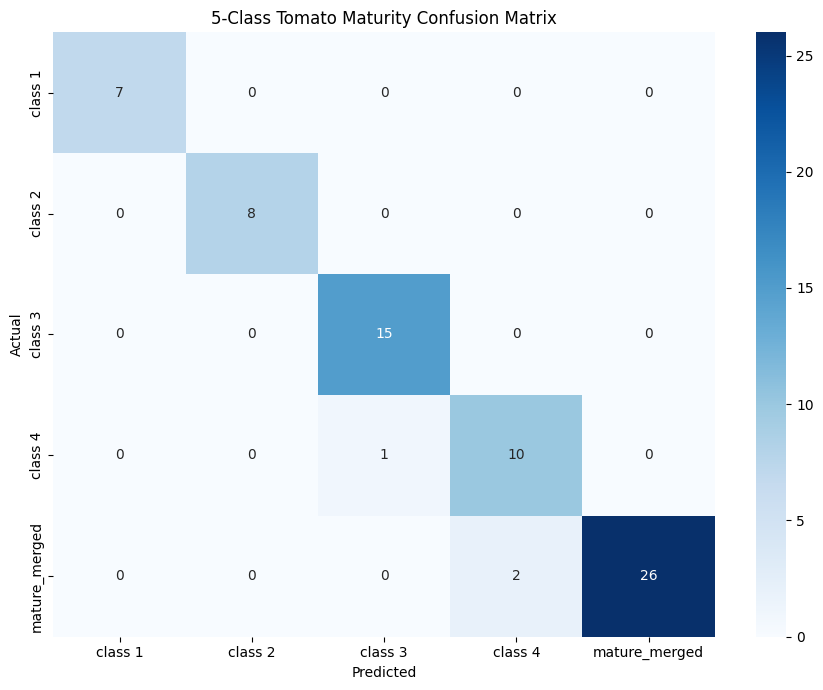

In [ ]:



model_5 = tf.keras.models.load_model(final_path)

y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = model_5.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print("Accuracy:",
      accuracy_score(y_true, y_pred) * 100)

print("Precision:",
      precision_score(y_true, y_pred, average="macro", zero_division=0) * 100)

print("Recall:",
      recall_score(y_true, y_pred, average="macro", zero_division=0) * 100)

print("F1:",
      f1_score(y_true, y_pred, average="macro", zero_division=0) * 100)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(5)),
    target_names=CLASS_NAMES,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(5)))

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("5-Class Tomato Maturity Confusion Matrix")
plt.tight_layout()
plt.show()

Saving Screenshot 2026-10-10 023459.png to Screenshot 2026-10-10 023459.png


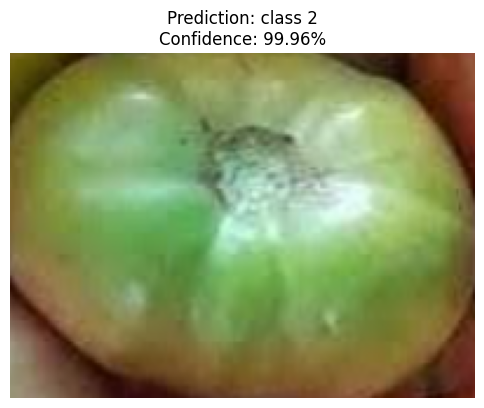


Image: Screenshot 2026-10-10 023459.png
Prediction: class 2
Confidence: 99.96%


In [ ]:


# Load trained model
model_5 = tf.keras.models.load_model(
    "/content/tomato_mobilenetv2_5classes.keras"
)

CLASS_NAMES = [
    "class 1",
    "class 2",
    "class 3",
    "class 4",
    "mature_merged"
]

# Upload images
uploaded = files.upload()

# Predict every uploaded image
for filename in uploaded.keys():

    img = Image.open(filename).convert("RGB")
    img_resized = img.resize((224, 224))

    img_array = np.array(img_resized, dtype=np.float32)
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    predictions = model_5.predict(img_array, verbose=0)[0]

    predicted_index = np.argmax(predictions)
    predicted_class = CLASS_NAMES[predicted_index]
    confidence = predictions[predicted_index] * 100

    # Show image and prediction
    plt.figure(figsize=(6, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.show()

    print(f"\nImage: {filename}")
    print(f"Prediction: {predicted_class}")
    print(f"Confidence: {confidence:.2f}%")

In [ ]:


MODEL_PATH = "/content/tomato_mobilenetv2_5classes.keras"

# Save complete model (Architecture + Weights)
model_5.save(MODEL_PATH)

# Save class names
CLASS_NAMES = [
    "class 1",
    "class 2",
    "class 3",
    "class 4",
    "mature_merged"
]

with open("/content/class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f, indent=4)

print("Model saved successfully!")
print("Size:", round(os.path.getsize(MODEL_PATH) / 1024**2, 2), "MB")

Model saved successfully!
Size: 22.6 MB


In [ ]:
from google.colab import files

files.download(
    "/content/tomato_mobilenetv2_5classes.keras"
)

files.download(
    "/content/class_names.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>